In [2]:
import ast, numpy as np, pandas as pd, wfdb
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
DATA_DIR = Path.cwd().parent/ "data"
from collections import Counter
METADATA_FILE = DATA_DIR / "ptbxl_database.csv"
STATEMENTS_FILE = DATA_DIR / "scp_statements.csv"
df = pd.read_csv(METADATA_FILE)
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval) # string -> dict
scp = pd.read_csv(STATEMENTS_FILE, index_col=0)

In [3]:
print(scp.head(2))

                         description  diagnostic  form  rhythm  \
NDT   non-diagnostic T abnormalities         1.0   1.0     NaN   
NST_         non-specific ST changes         1.0   1.0     NaN   

     diagnostic_class diagnostic_subclass  \
NDT              STTC                STTC   
NST_             STTC                NST_   

                                     Statement Category  \
NDT                   other ST-T descriptive statements   
NST_  Basic roots for coding ST-T changes and abnorm...   

       SCP-ECG Statement Description  AHA code            aECG REFID  \
NDT   non-diagnostic T abnormalities       NaN                   NaN   
NST_         non-specific ST changes     145.0  MDC_ECG_RHY_STHILOST   

     CDISC Code DICOM Code  
NDT         NaN        NaN  
NST_        NaN        NaN  


In [4]:
print(df.shape) # about (21799, 27): rows = ECG recordings
df.head()
df.info()

(21799, 28)
<class 'pandas.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ecg_id                        21799 non-null  int64  
 1   patient_id                    21799 non-null  float64
 2   age                           21799 non-null  float64
 3   sex                           21799 non-null  int64  
 4   height                        6974 non-null   float64
 5   weight                        9421 non-null   float64
 6   nurse                         20326 non-null  float64
 7   site                          21782 non-null  float64
 8   device                        21799 non-null  str    
 9   recording_date                21799 non-null  str    
 10  report                        21799 non-null  str    
 11  scp_codes                     21799 non-null  object 
 12  heart_axis                    13331 non-null  str    
 13  

In [5]:
print(df.scp_codes.iloc[0])

diag = scp[scp.diagnostic == 1]                  # keep only diagnostic codes
print(diag.diagnostic_class.value_counts())      # NORM, MI, STTC, CD, HYP

def to_classes(codes):
    return sorted({diag.loc[c].diagnostic_class for c in codes if c in diag.index})

df['classes'] = df.scp_codes.apply(to_classes)
df[['scp_codes', 'classes']].head()              # check the result

{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


,scp_codes,classes
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
1,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
2,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
3,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]


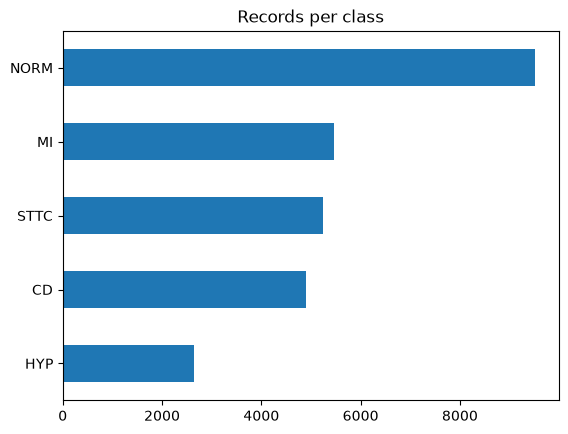

411 records have no diagnostic class
classes
1    16244
2     4068
3      919
0      411
4      157
Name: count, dtype: int64
electrodes_problems    0.998624
infarction_stadium2    0.995275
pacemaker              0.986651
burst_noise            0.971879
baseline_drift         0.926694
extra_beats            0.910592
static_noise           0.850452
infarction_stadium1    0.742557
height                 0.680077
weight                 0.567824
validated_by           0.430203
heart_axis             0.388458
nurse                  0.067572
site                   0.000780
filename_lr            0.000000
dtype: float64


In [6]:
cnt = pd.Series(Counter(c for cl in df.classes for c in cl)).sort_values()
cnt.plot.barh(title='Records per class'); plt.show()
print((df.classes.str.len() == 0).sum(), 'records have no diagnostic class')
print(df.classes.str.len().value_counts())      
print(df.isna().mean().sort_values(ascending=False).head(15))

In [7]:
print(df.isna().mean().sort_values(ascending=False).head(15))

electrodes_problems    0.998624
infarction_stadium2    0.995275
pacemaker              0.986651
burst_noise            0.971879
baseline_drift         0.926694
extra_beats            0.910592
static_noise           0.850452
infarction_stadium1    0.742557
height                 0.680077
weight                 0.567824
validated_by           0.430203
heart_axis             0.388458
nurse                  0.067572
site                   0.000780
filename_lr            0.000000
dtype: float64


In [8]:
print('patients:', df.patient_id.nunique(), ' records:', len(df))
print(df.groupby('patient_id').size().value_counts().head())

patients: 18869  records: 21799
1    16758
2     1590
3      350
4       99
5       43
Name: count, dtype: int64


In [9]:
df[['age', 'height', 'weight']].describe()

,age,height,weight
count,21799.000000,6974.000000,9421.000000
mean,62.769301,166.702323,70.995223
std,32.308813,10.867321,15.878803
min,2.000000,6.000000,5.000000
25%,50.000000,160.000000,60.000000
50%,62.000000,166.000000,70.000000
75%,72.000000,174.000000,80.000000
max,300.000000,209.000000,250.000000


In [10]:
df['age_clean'] = df.age.where(df.age <= 120, 90)

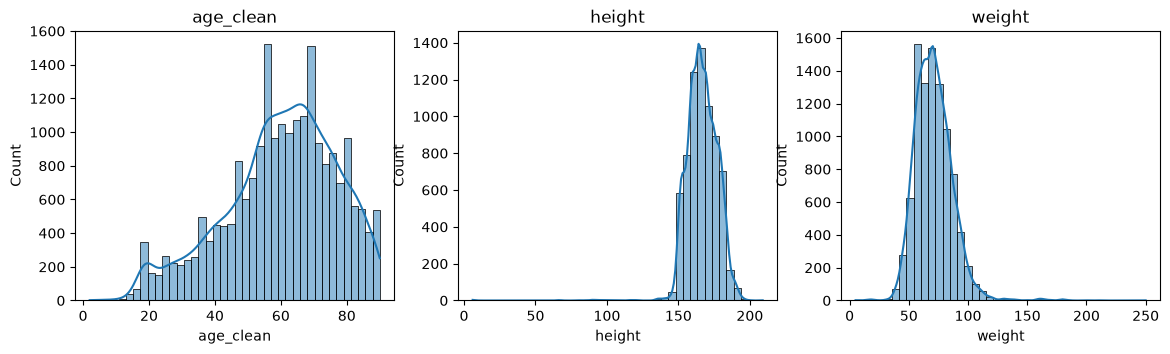

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ['age_clean', 'height', 'weight']):
    sns.histplot(df[c].dropna(), bins=40, ax=a, kde=True); a.set_title(c)
plt.show()

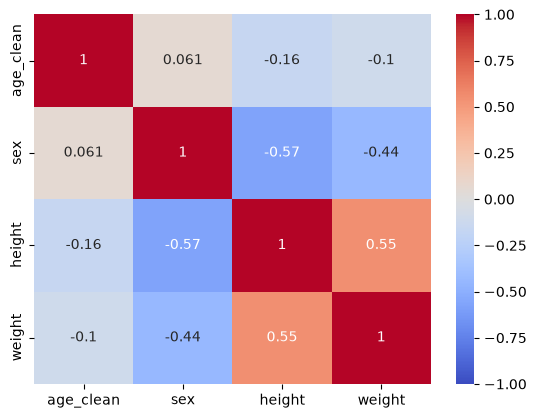

In [12]:
corr = df[['age_clean', 'sex', 'height', 'weight']].corr(method='pearson')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1); plt.show()

age_clean 92 outliers
height 34 outliers
weight 127 outliers


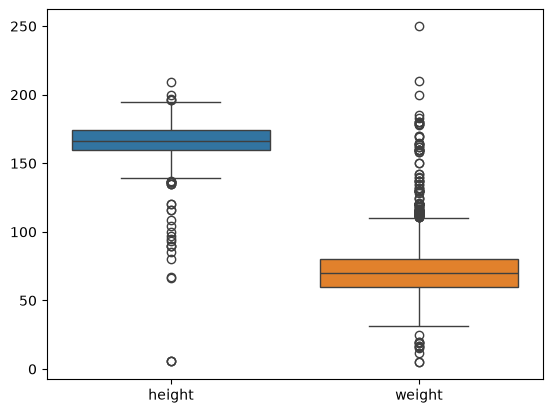

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]);
    i = q3 - q1 
    return s[(s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)]
for c in ['age_clean', 'height', 'weight']:
    print(c, len(iqr_outliers(df[c].dropna())), 'outliers')
sns.boxplot(data=df[['height', 'weight']]); 
plt.show()

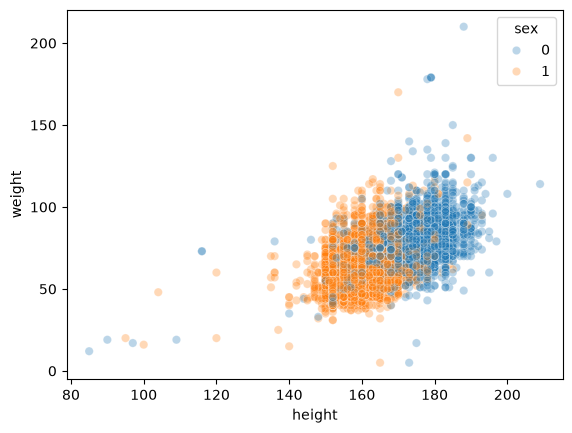

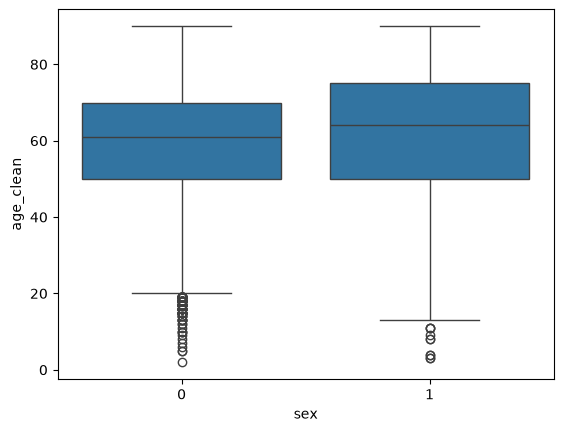

,age_clean,height,weight,bmi
sex,,,,
0,58.944337,173.491999,78.506440,25.825977
1,61.036285,160.988381,64.557461,24.703968


In [14]:
sns.scatterplot(data=df, x='height', y='weight', hue='sex', alpha=.3); plt.show()
sns.boxplot(data=df, x='sex', y='age_clean'); plt.show()
df['bmi'] = df.weight / (df.height / 100) ** 2
df.groupby('sex')[['age_clean', 'height', 'weight', 'bmi']].mean()


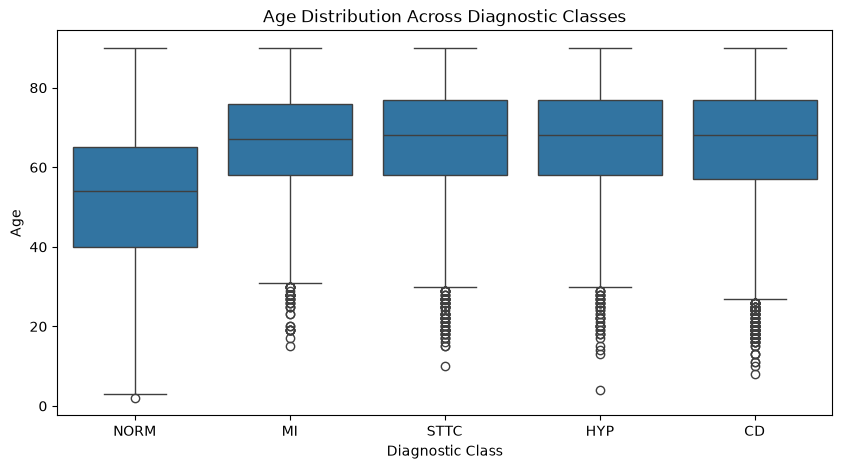

Sex Distribution Per Diagnostic Class:
sex          0      1
classes              
CD       0.612  0.388
HYP      0.574  0.426
MI       0.623  0.377
NORM     0.461  0.539
STTC     0.490  0.510


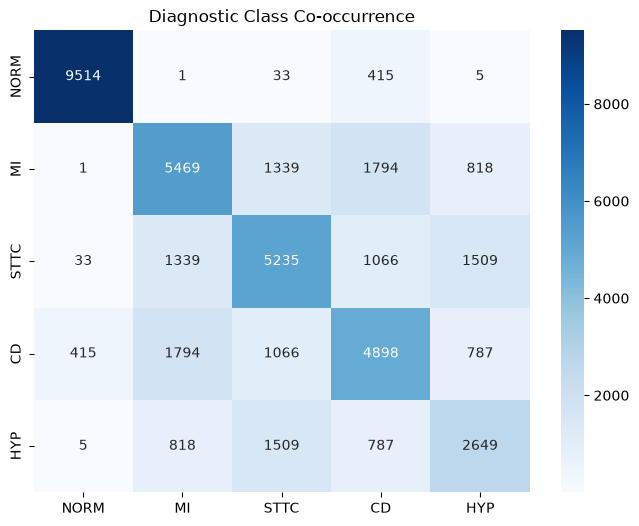

In [15]:

# Explode diagnostic classes and reset index
ex = (
    df.explode('classes')
      .dropna(subset=['classes'])
      .reset_index(drop=True)
)

# 1. Age distribution per diagnostic class
plt.figure(figsize=(10, 5))
sns.boxplot(data=ex, x='classes', y='age_clean')
plt.title('Age Distribution Across Diagnostic Classes')
plt.xlabel('Diagnostic Class')
plt.ylabel('Age')
plt.show()

# 2. Sex distribution per diagnostic class
sex_distribution = pd.crosstab(
    ex['classes'],
    ex['sex'],
    normalize='index'
)

print("Sex Distribution Per Diagnostic Class:")
print(sex_distribution.round(3))

# 3. Diagnostic classes co-occurrence
labels = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

M = pd.DataFrame({
    c: df['classes'].apply(
        lambda values: int(c in values)
        if isinstance(values, (list, tuple, set))
        else 0
    )
    for c in labels
})

cooccurrence = M.T.dot(M)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cooccurrence,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title('Diagnostic Class Co-occurrence')
plt.show()


In [30]:
# pip install pandas numpy wfdb scipy scikit-learn torch tqdm
# Notebook friendly: each "# %%" block is one cell.

# %% ---------------- 0. ALL LIBRARIES ----------------
import ast
import numpy as np
import pandas as pd
import wfdb
from tqdm import tqdm
from scipy.signal import butter, sosfiltfilt, decimate

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score

PATH = 'ptb-xl/'
SR = 100                      # 100 -> records100 (1000 samples), 500 -> records500 (decimated to 100 Hz)
LIK_MIN = 0                   # set to 50 to keep only codes with likelihood >= 50
LABELS = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

# %% ---------------- 1. LOAD METADATA + LABELS ----------------
df = pd.read_csv(PATH + 'ptbxl_database.csv', index_col='ecg_id')
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)
scp = pd.read_csv(PATH + 'scp_statements.csv', index_col=0)
diag = scp[scp.diagnostic == 1]

def to_classes(codes):
    return sorted({diag.loc[c].diagnostic_class
                   for c, p in codes.items() if c in diag.index and p >= LIK_MIN})
df['classes'] = df.scp_codes.apply(to_classes)

# %% ---------------- 2. CLEAN + PREPARE DATA ----------------
# 2.1 labels (multi-hot), drop unlabeled records
d = df[df.classes.str.len() > 0].copy()
for c in LABELS:
    d[c] = d.classes.apply(lambda l: int(c in l))
Y = d[LABELS].values.astype('float32')

# 2.2 metadata: age 300 -> 90, impossible values -> NaN, fill with median
d['age_clean'] = d.age.where(d.age <= 120, 90)
d.loc[d.age_clean < 0, 'age_clean'] = np.nan
d['age_clean'] = d.age_clean.fillna(d.age_clean.median())
d['sex'] = d.sex.fillna(d.sex.mode()[0])
meta_feat = np.c_[d.age_clean.values / 100, d.sex.values].astype('float32')   # age + sex only

# 2.3 signal cleaning: band-pass 0.5-40 Hz (+ decimate if using 500 Hz files)
sos = butter(3, [0.5, 40], btype='band', fs=100, output='sos')

def load(row):
    f = row.filename_lr if SR == 100 else row.filename_hr
    sig, meta = wfdb.rdsamp(PATH + f)
    return sig

def clean(sig):
    if SR != 100:
        sig = decimate(sig, SR // 100, axis=0)
    return sosfiltfilt(sos, sig, axis=0).astype('float32')

X = np.stack([clean(load(r)) for _, r in tqdm(d.iterrows(), total=len(d))])   # (N, 1000, 12)

# 2.4 integrity checks: drop records with NaN or flat leads
bad = np.isnan(X).any((1, 2)) | (X.std(1) < 1e-4).any(1)
print('dropping broken signals:', bad.sum())
keep = ~bad
X, Y, meta_feat, d = X[keep], Y[keep], meta_feat[keep], d[keep]

np.save('X.npy', X); np.save('Y.npy', Y); np.save('meta.npy', meta_feat)
d.to_pickle('d.pkl')
print(X.shape, Y.shape, meta_feat.shape)       # (N,1000,12) (N,5) (N,2)

# %% ---------------- 3. SPLIT (patient-level, PTB-XL folds) ----------------
itr = (d.strat_fold <= 8).values
iva = (d.strat_fold == 9).values
ite = (d.strat_fold == 10).values
Xtr, Xva, Xte = X[itr], X[iva], X[ite]
Ytr, Yva, Yte = Y[itr], Y[iva], Y[ite]
Mtr, Mva, Mte = meta_feat[itr], meta_feat[iva], meta_feat[ite]

# no patient overlap check (all must be 0)
sets = {'train': set(d[itr].patient_id), 'val': set(d[iva].patient_id), 'test': set(d[ite].patient_id)}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    print(a, b, 'shared patients:', len(sets[a] & sets[b]))

# normalize per lead using TRAIN statistics only
mu, sd = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-8
Xtr, Xva, Xte = [((x - mu) / sd).astype('float32') for x in (Xtr, Xva, Xte)]
np.savez('norm_stats.npz', mean=mu, std=sd)

print(pd.DataFrame({'train': Ytr.mean(0), 'val': Yva.mean(0), 'test': Yte.mean(0)}, index=LABELS))

# %% ---------------- 4. MODEL: CardioNetV2 (multi-scale ResNet + Transformer) ----------------
class MSBlock(nn.Module):
    """Residual block with 3 parallel kernel sizes (3, 7, 15) to catch beats at different scales."""
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        b = cout // 3
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv1d(cin, b, k, stride, k // 2, bias=False), nn.BatchNorm1d(b))
            for k in (3, 7, 15)])
        self.mix = nn.Sequential(nn.ReLU(), nn.Conv1d(3 * b, cout, 1, bias=False), nn.BatchNorm1d(cout))
        self.short = (nn.Identity() if cin == cout and stride == 1 else
                      nn.Sequential(nn.Conv1d(cin, cout, 1, stride, bias=False), nn.BatchNorm1d(cout)))
        self.act = nn.ReLU()
    def forward(self, x):
        y = torch.cat([br(x) for br in self.branches], 1)
        return self.act(self.mix(y) + self.short(x))

class CardioNetV2(nn.Module):
    def __init__(self, n_leads=12, n_classes=5, n_meta=2, dim=192, heads=4, layers=2, drop=0.2):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv1d(n_leads, 96, 15, 2, 7, bias=False),
                                  nn.BatchNorm1d(96), nn.ReLU())                      # 1000 -> 500
        self.cnn = nn.Sequential(MSBlock(96, 96), MSBlock(96, dim, 2),                # 250
                                 MSBlock(dim, dim, 2), MSBlock(dim, dim, 2))          # 125 -> 63
        self.pos = nn.Parameter(torch.zeros(1, 128, dim))
        enc = nn.TransformerEncoderLayer(dim, heads, dim * 2, drop, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(enc, layers)
        self.meta = nn.Sequential(nn.Linear(n_meta, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * dim + 32, 128), nn.ReLU(),
                                  nn.Dropout(drop), nn.Linear(128, n_classes))
    def forward(self, x, m):                       # x: (B,12,1000)  m: (B,2)
        h = self.cnn(self.stem(x)).transpose(1, 2)           # (B, T, dim)
        h = self.tr(h + self.pos[:, :h.size(1)])
        z = torch.cat([h.mean(1), h.amax(1), self.meta(m)], 1)
        return self.head(z)                                   # logits

# %% ---------------- 5. TRAIN ----------------
torch.manual_seed(0); np.random.seed(0)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
T = lambda a: torch.tensor(a)
mk = lambda X_, M_, Y_, sh: DataLoader(TensorDataset(T(X_).permute(0, 2, 1), T(M_), T(Y_)), 64, shuffle=sh)
tr, va, te = mk(Xtr, Mtr, Ytr, True), mk(Xva, Mva, Yva, False), mk(Xte, Mte, Yte, False)

model = CardioNetV2().to(dev)
pos = Ytr.mean(0)
crit = nn.BCEWithLogitsLoss(pos_weight=T((1 - pos) / pos).to(dev))     # class imbalance
EP = 40
opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=EP * len(tr))

def predict(loader):
    model.eval(); P, Tt = [], []
    with torch.no_grad():
        for x, m, y in loader:
            P.append(torch.sigmoid(model(x.to(dev), m.to(dev))).cpu()); Tt.append(y)
    return torch.cat(P).numpy(), torch.cat(Tt).numpy()

best = 0
for ep in range(EP):
    model.train()
    for x, m, y in tr:
        x, m, y = x.to(dev), m.to(dev), y.to(dev)
        # light augmentation: random amplitude scale + small noise
        x = x * (1 + 0.1 * torch.randn(x.size(0), 1, 1, device=dev)) + 0.01 * torch.randn_like(x)
        opt.zero_grad(); loss = crit(model(x, m), y); loss.backward(); opt.step(); sched.step()
    P, Tv = predict(va); auc = roc_auc_score(Tv, P, average='macro')
    print(ep + 1, round(loss.item(), 3), 'val AUC', round(auc, 4))
    if auc > best:
        best = auc; torch.save(model.state_dict(), 'cardionet.pt')

# %% ---------------- 6. EVALUATE (test fold used once) ----------------
model.load_state_dict(torch.load('cardionet.pt', map_location=dev))
Pv, Tv = predict(va)
th = [max(np.linspace(.05, .95, 91), key=lambda t: f1_score(Tv[:, i], Pv[:, i] > t)) for i in range(5)]

P, Tt = predict(te)
for i, c in enumerate(LABELS):
    print(c, 'AUC', round(roc_auc_score(Tt[:, i], P[:, i]), 4),
          'F1', round(f1_score(Tt[:, i], P[:, i] > th[i]), 4))
print('macro AUC', round(roc_auc_score(Tt, P, average='macro'), 4))

FileNotFoundError: [Errno 2] No such file or directory: 'ptb-xl/ptbxl_database.csv'